# ICS 471 Deep Learning – Milestone 2: Data Pipeline and MLP Networks

**Team:** Abdulaziz Alguraini (202255320), Bader Alqahatani (202274680)
**Section:** 01
**Dataset:** Arabic Handwritten Characters Dataset (AHCD)

In this milestone we build a reusable PyTorch data pipeline for AHCD and use it to train two multilayer perceptrons: a shallow MLP with two hidden layers and a deeper MLP with five hidden layers. We compare three loss functions and three optimizers on the shallow network, tune the learning rate for the best combination, and then compare the two networks on the test set.

## 0. Setup

In [1]:
import copy
import glob
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
DATA_DIR = "data"
IMAGE_SIZE = 32
BATCH_SIZE = 64
EPOCHS = 30
DROPOUT = 0.2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

LETTERS = [
    "alef", "beh", "teh", "theh", "jeem", "hah", "khah", "dal", "thal", "reh",
    "zain", "seen", "sheen", "sad", "dad", "tah", "zah", "ain", "ghain", "feh",
    "qaf", "kaf", "lam", "meem", "noon", "heh", "waw", "yeh",
]
CLASS_NAMES = {i + 1: name for i, name in enumerate(LETTERS)}

pd.set_option("display.precision", 4)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

PyTorch version: 2.14.0+cpu
Device: cpu


## 1. Data Pipeline

The pipeline is split into small methods:

- `load_ahcd` loads the four CSV files.
- `show_samples` displays one image from each class.
- `split_data` uses the official test set when it exists, otherwise it makes an 80/20 train/test split. It then splits the training data 80/20 into training and validation. All splits are stratified.
- `Preprocessor` reshapes the images, normalizes them, encodes the labels and converts everything to PyTorch tensors. Its parameters are fitted on the training split only.
- `make_loaders` creates the DataLoader objects.
- `build_data_pipeline` runs all of the above in order.

### 1.1 Loading the data and displaying one sample per class

In [2]:
def find_csv(data_dir, *keywords):
    paths = glob.glob(os.path.join(data_dir, "**", "*.csv"), recursive=True)
    matches = [p for p in paths if all(k in os.path.basename(p).lower() for k in keywords)]
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected one CSV matching {keywords} in '{data_dir}', found: {matches}")
    return matches[0]


def load_ahcd(data_dir=DATA_DIR):
    def read(*keywords):
        return pd.read_csv(find_csv(data_dir, *keywords), header=None).values

    X_train = read("train", "image").astype(np.float32)
    y_train = read("train", "label").ravel()
    X_test = read("test", "image").astype(np.float32)
    y_test = read("test", "label").ravel()
    return X_train, y_train, X_test, y_test


def to_images(X, size=IMAGE_SIZE, transpose=True):
    images = X.reshape(-1, size, size)
    return images.transpose(0, 2, 1) if transpose else images


def show_samples(X, y, class_names, seed=SEED, cols=7):
    rng = np.random.default_rng(seed)
    images = to_images(X)
    classes = np.unique(y)
    rows = int(np.ceil(len(classes) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.5, rows * 1.7))
    for ax in axes.flat:
        ax.axis("off")
    for ax, c in zip(axes.flat, classes):
        idx = rng.choice(np.where(y == c)[0])
        ax.imshow(images[idx], cmap="gray")
        ax.set_title(f"{c}: {class_names.get(c, c)}", fontsize=9)
    fig.suptitle("AHCD: one training sample from each class", fontsize=13)
    plt.tight_layout()
    plt.show()

### 1.2 Preprocessing

Our preprocessing steps are:

1. **Reshaping.** AHCD stores each image column by column, so we reshape each row to 32×32 and transpose it to get the letter in the correct orientation. We then flatten it back to a 1024-long vector because an MLP expects a vector input.
2. **Normalization.** Pixels are scaled from [0, 255] to [0, 1] and then standardized with the mean and standard deviation of the **training split only**.
3. **Label encoding.** The labels 1–28 are mapped to 0–27 with `LabelEncoder`, which is the format `CrossEntropyLoss` expects. The encoder is also fitted on the training split only.
4. **Conversion to tensors.** Features become `float32` tensors and labels become `long` tensors.

In [3]:
class Preprocessor:
    def __init__(self, size=IMAGE_SIZE, transpose=True):
        self.size = size
        self.transpose = transpose
        self.mean = None
        self.std = None
        self.encoder = LabelEncoder()

    def fit(self, X, y):
        pixels = X.astype(np.float32) / 255.0
        self.mean = float(pixels.mean())
        self.std = float(pixels.std())
        self.encoder.fit(y)
        return self

    def transform(self, X, y):
        images = to_images(X, self.size, self.transpose).astype(np.float32) / 255.0
        images = (images - self.mean) / self.std
        features = images.reshape(len(images), -1)
        labels = self.encoder.transform(y)
        return torch.tensor(features, dtype=torch.float32), torch.tensor(labels, dtype=torch.long)

### 1.3 Splitting the data

In [4]:
def split_data(X, y, X_test=None, y_test=None, test_size=0.2, val_size=0.2, seed=SEED):
    if X_test is None or y_test is None:
        X, X_test, y, y_test = train_test_split(X, y, test_size=test_size, stratify=y, random_state=seed)
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=val_size, stratify=y, random_state=seed)
    return X_train, y_train, X_val, y_val, X_test, y_test

### 1.4 DataLoaders and the full pipeline

In [5]:
def make_loaders(train_ds, val_ds, test_ds, batch_size=BATCH_SIZE):
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=256, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=256, shuffle=False)
    return train_loader, val_loader, test_loader


def build_data_pipeline(data_dir=DATA_DIR, batch_size=BATCH_SIZE, show=True):
    X_full, y_full, X_test, y_test = load_ahcd(data_dir)
    print(f"Official training set: {X_full.shape[0]} images | official test set: {X_test.shape[0]} images")
    print(f"Pixel range: {X_full.min():.0f} to {X_full.max():.0f} | classes: {len(np.unique(y_full))}")
    if show:
        show_samples(X_full, y_full, CLASS_NAMES)

    X_train, y_train, X_val, y_val, X_test, y_test = split_data(X_full, y_full, X_test, y_test)
    prep = Preprocessor().fit(X_train, y_train)

    train_ds = TensorDataset(*prep.transform(X_train, y_train))
    val_ds = TensorDataset(*prep.transform(X_val, y_val))
    test_ds = TensorDataset(*prep.transform(X_test, y_test))
    loaders = make_loaders(train_ds, val_ds, test_ds, batch_size)

    counts = pd.DataFrame({
        "split": ["train", "validation", "test"],
        "images": [len(y_train), len(y_val), len(y_test)],
        "min per class": [pd.Series(s).value_counts().min() for s in (y_train, y_val, y_test)],
        "max per class": [pd.Series(s).value_counts().max() for s in (y_train, y_val, y_test)],
    })
    display(counts)
    return loaders, prep

Official training set: 13440 images | official test set: 3360 images
Pixel range: 0 to 255 | classes: 28


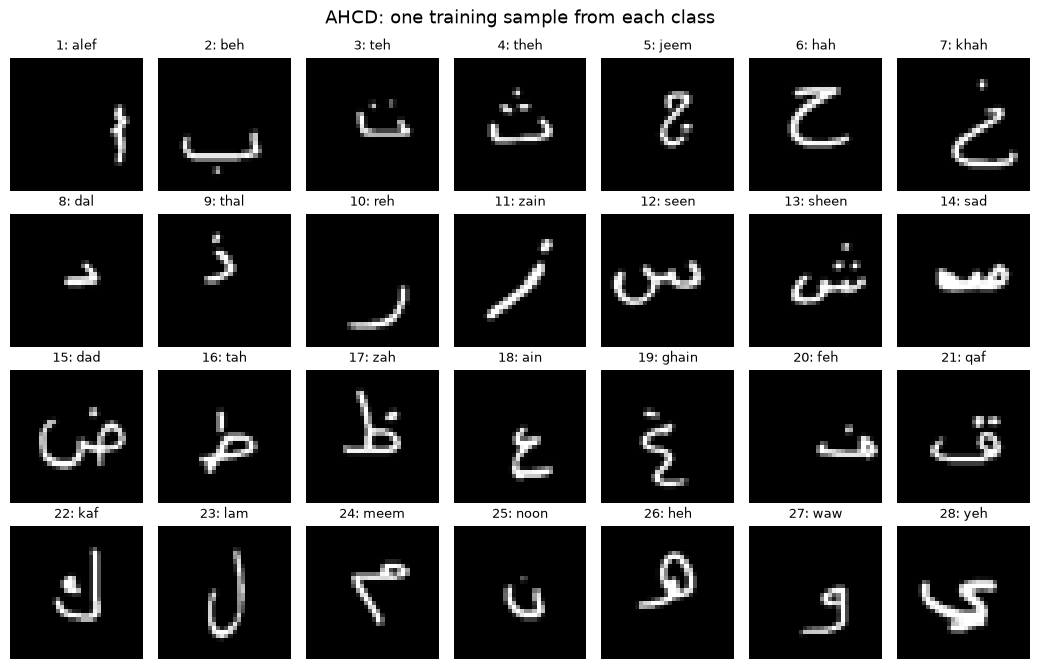

,split,images,min per class,max per class
0,train,10752,384,384
1,validation,2688,96,96
2,test,3360,120,120


Training mean / std used for normalization: 0.0528 / 0.1945
Label encoding (original -> encoded): {1: 0, 2: 1, 3: 2, 4: 3, 5: 4} ...
train      tensor shape (10752, 1024) | mean 0.0000 | std 1.0000
validation tensor shape (2688, 1024) | mean 0.0030 | std 1.0057
test       tensor shape (3360, 1024) | mean 0.0023 | std 1.0050
One training batch: (64, 1024) torch.float32 (64,) torch.int64
Input dimension: 1024 | number of classes: 28


In [6]:
(train_loader, val_loader, test_loader), prep = build_data_pipeline()

print(f"Training mean / std used for normalization: {prep.mean:.4f} / {prep.std:.4f}")
first = prep.encoder.classes_[:5]
print("Label encoding (original -> encoded):", dict(zip(first.tolist(), prep.encoder.transform(first).tolist())), "...")

for name, loader in [("train", train_loader), ("validation", val_loader), ("test", test_loader)]:
    features = loader.dataset.tensors[0]
    print(f"{name:<10} tensor shape {tuple(features.shape)} | mean {features.mean():.4f} | std {features.std():.4f}")

xb, yb = next(iter(train_loader))
print("One training batch:", tuple(xb.shape), xb.dtype, tuple(yb.shape), yb.dtype)

INPUT_DIM = train_loader.dataset.tensors[0].shape[1]
NUM_CLASSES = len(prep.encoder.classes_)
print("Input dimension:", INPUT_DIM, "| number of classes:", NUM_CLASSES)

AHCD comes with an official test set (3,360 images), so we keep it for the final evaluation and do not make our own train/test split. The official training set is split 80/20 into training (10,752) and validation (2,688), stratified by class. The table shows that every class keeps the same share in each split. Our proposal planned an 85/15 train/validation split, but this milestone asks for 80/20, so we use 80/20 from now on.

The training features have a mean of about 0 and a standard deviation of about 1 because the normalization was fitted on them. The validation and test features are close to that but not exactly, which confirms that their statistics were not used.

## 2. MLP Implementation

In [7]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, num_classes, activation=nn.ReLU, dropout=DROPOUT):
        super().__init__()
        layers = []
        prev = input_dim
        for units in hidden_dims:
            layers += [nn.Linear(prev, units), activation(), nn.Dropout(dropout)]
            prev = units
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


SHALLOW_HIDDEN = [512, 256]
DEEP_HIDDEN = [512, 256, 256, 128, 128]

shallow_example = MLP(INPUT_DIM, SHALLOW_HIDDEN, NUM_CLASSES)
deep_example = MLP(INPUT_DIM, DEEP_HIDDEN, NUM_CLASSES)
print(shallow_example)
print(f"Shallow MLP parameters: {count_parameters(shallow_example):,}")
print(f"Deep MLP parameters:    {count_parameters(deep_example):,}")

MLP(
  (net): Sequential(
    (0): Linear(in_features=1024, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=256, out_features=28, bias=True)
  )
)
Shallow MLP parameters: 663,324
Deep MLP parameters:    774,940


**Number of neurons.** The input has 1,024 values and the output has 28 classes, so we use a funnel shape that roughly halves the width at each layer: 1024 → 512 → 256 → 28 for the shallow MLP. The first layer is wide enough to learn many stroke and dot patterns, and the second compresses them before the output. The deep MLP keeps the same first two layers and adds three more (256, 128, 128), so the difference between the two networks is mostly depth rather than width.

**Activation function.** We use ReLU in all hidden layers. It is cheap to compute and does not saturate for positive inputs, so it avoids the vanishing gradients that sigmoid or tanh can cause, which matters more in the five-layer network. Each hidden layer is followed by dropout (p = 0.2) as regularization.

**Output layer.** The output is a linear layer with 28 units that returns one logit per letter. We do not add a softmax layer because `CrossEntropyLoss` (and our focal loss) apply log-softmax internally. The predicted class is the argmax of the logits.

The class takes the list of hidden layer sizes as an argument, so the same code builds both networks.

## 3. Required Experiments

### 3.1 Loss functions

AHCD is a multi-class classification task, so we use three classification losses:

- **Cross-entropy:** the standard loss for multi-class classification.
- **Cross-entropy with label smoothing (0.1):** the target puts 0.9 on the correct letter and spreads 0.1 over the others. This keeps the model from becoming overconfident, which can help with letters that differ only by dots (beh/teh/theh).
- **Focal loss (γ = 2):** multiplies the cross-entropy by (1 − p)^γ, so easy, confidently correct images contribute less and the model focuses on the hard, confusable ones.

In [8]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction="none")
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()


LOSSES = ["CrossEntropy", "CE + Label Smoothing", "Focal"]


def get_loss(name):
    if name == "CrossEntropy":
        return nn.CrossEntropyLoss()
    if name == "CE + Label Smoothing":
        return nn.CrossEntropyLoss(label_smoothing=0.1)
    if name == "Focal":
        return FocalLoss(gamma=2.0)
    raise ValueError(f"Unknown loss: {name}")

### 3.2 Optimizers

We use SGD with momentum (0.9), RMSprop and Adam. For the 3×3 comparison each optimizer uses its usual default learning rate (0.01 for SGD, 0.001 for RMSprop and Adam), because a single shared learning rate would be too small for SGD or too large for the adaptive methods. The learning rate is tuned separately in Section 3.6.

L2 regularization is applied through the optimizer's `weight_decay` argument.

In [9]:
OPTIMIZERS = ["SGD", "RMSprop", "Adam"]
DEFAULT_LR = {"SGD": 0.01, "RMSprop": 0.001, "Adam": 0.001}


def get_optimizer(name, params, lr=None, weight_decay=1e-4):
    lr = DEFAULT_LR[name] if lr is None else lr
    if name == "SGD":
        return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    if name == "RMSprop":
        return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    if name == "Adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    raise ValueError(f"Unknown optimizer: {name}")

### 3.3 Training and evaluation methods

`train_model` builds an MLP, trains it for a fixed number of epochs and records the training and validation loss and accuracy after every epoch. It keeps the weights from the epoch with the best **validation accuracy**. We select models by validation accuracy rather than validation loss because the three loss functions produce values on different scales, so their losses cannot be compared directly. Accuracy is also the validation metric we chose in our proposal, and it is suitable because AHCD is perfectly balanced.

In [10]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            count += len(yb)
    return total_loss / count, correct / count


def train_model(hidden_dims, train_loader, val_loader, loss_name, opt_name, lr=None,
                weight_decay=1e-4, epochs=EPOCHS, dropout=DROPOUT, seed=SEED, verbose=False):
    set_seed(seed)
    model = MLP(INPUT_DIM, hidden_dims, NUM_CLASSES, dropout=dropout).to(DEVICE)
    criterion = get_loss(loss_name)
    optimizer = get_optimizer(opt_name, model.parameters(), lr, weight_decay)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_epoch, best_state = -1.0, 0, None
    start = time.time()

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        for key, value in zip(history, [train_loss, train_acc, val_loss, val_acc]):
            history[key].append(value)
        if val_acc > best_acc:
            best_acc, best_epoch = val_acc, epoch
            best_state = copy.deepcopy(model.state_dict())
        if verbose and (epoch == 1 or epoch % 5 == 0):
            print(f"epoch {epoch:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} "
                  f"| val loss {val_loss:.4f} acc {val_acc:.4f}")

    model.load_state_dict(best_state)
    result = {
        "loss": loss_name,
        "optimizer": opt_name,
        "lr": DEFAULT_LR[opt_name] if lr is None else lr,
        "weight_decay": weight_decay,
        "best_val_acc": best_acc,
        "best_epoch": best_epoch,
        "final_train_acc": history["train_acc"][-1],
        "time_s": time.time() - start,
    }
    return model, history, result


def describe(result):
    return (f"{result['loss']:<20} {result['optimizer']:<8} lr={result['lr']:<7g} "
            f"wd={result['weight_decay']:<7g} best val acc={result['best_val_acc']:.4f} "
            f"(epoch {result['best_epoch']:2d})  {result['time_s']:.1f}s")


def predict(model, loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.append(model(xb.to(DEVICE)).argmax(dim=1).cpu())
            targets.append(yb)
    return torch.cat(preds).numpy(), torch.cat(targets).numpy()


def evaluate_on_test(model, loader, loss_name):
    test_loss, test_acc = run_epoch(model, loader, get_loss(loss_name))
    preds, targets = predict(model, loader)
    return {"test loss": test_loss, "test acc": test_acc,
            "test macro F1": f1_score(targets, preds, average="macro")}


def plot_history(history, best_epoch, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(epochs, history["train_loss"], label="Training")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set_title(f"{title}: loss vs. epoch")
    axes[0].set_ylabel("Loss")
    axes[1].plot(epochs, history["train_acc"], label="Training")
    axes[1].plot(epochs, history["val_acc"], label="Validation")
    axes[1].set_title(f"{title}: accuracy vs. epoch")
    axes[1].set_ylabel("Accuracy")
    for ax in axes:
        ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1, label=f"Best epoch ({best_epoch})")
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

### 3.4 Regularization strength

We use two forms of regularization: dropout (p = 0.2) after every hidden layer, and L2 weight decay in the optimizer. To choose the L2 strength λ, we trained the shallow MLP with cross-entropy and Adam at three values and kept the one with the best validation accuracy. The selected λ is then used in every later experiment.

In [11]:
WD_CANDIDATES = [1e-5, 1e-4, 1e-3]
wd_results = []
for wd in WD_CANDIDATES:
    _, _, res = train_model(SHALLOW_HIDDEN, train_loader, val_loader, "CrossEntropy", "Adam", weight_decay=wd)
    wd_results.append(res)
    print(describe(res))

wd_df = pd.DataFrame(wd_results)[["weight_decay", "best_val_acc", "best_epoch", "final_train_acc", "time_s"]]
display(wd_df)

BEST_WD = float(wd_df.loc[wd_df["best_val_acc"].idxmax(), "weight_decay"])
print(f"Selected regularization strength: L2 weight decay λ = {BEST_WD:g}, dropout p = {DROPOUT}")

CrossEntropy         Adam     lr=0.001   wd=1e-05   best val acc=0.7738 (epoch 26)  91.3s
CrossEntropy         Adam     lr=0.001   wd=0.0001  best val acc=0.7705 (epoch 19)  91.6s
CrossEntropy         Adam     lr=0.001   wd=0.001   best val acc=0.7615 (epoch 25)  91.9s


,weight_decay,best_val_acc,best_epoch,final_train_acc,time_s
0,1.0000e-05,0.7738,26,0.9607,91.3433
1,1.0000e-04,0.7705,19,0.9550,91.6428
2,1.0000e-03,0.7615,25,0.9200,91.8548


Selected regularization strength: L2 weight decay λ = 1e-05, dropout p = 0.2


### 3.5 Loss × optimizer comparison (shallow MLP)

We train the shallow MLP with all nine combinations of the three losses and three optimizers, using the same data, epochs, seed and regularization strength. The best combination is the one with the highest validation accuracy.

In [12]:
grid_results = []
for loss_name in LOSSES:
    for opt_name in OPTIMIZERS:
        _, _, res = train_model(SHALLOW_HIDDEN, train_loader, val_loader, loss_name, opt_name,
                                weight_decay=BEST_WD)
        grid_results.append(res)
        print(describe(res))

CrossEntropy         SGD      lr=0.01    wd=1e-05   best val acc=0.7567 (epoch 28)  77.5s
CrossEntropy         RMSprop  lr=0.001   wd=1e-05   best val acc=0.7667 (epoch 28)  81.9s
CrossEntropy         Adam     lr=0.001   wd=1e-05   best val acc=0.7738 (epoch 26)  104.6s
CE + Label Smoothing SGD      lr=0.01    wd=1e-05   best val acc=0.7719 (epoch 30)  80.0s
CE + Label Smoothing RMSprop  lr=0.001   wd=1e-05   best val acc=0.7794 (epoch 22)  88.3s
CE + Label Smoothing Adam     lr=0.001   wd=1e-05   best val acc=0.7790 (epoch 25)  96.2s
Focal                SGD      lr=0.01    wd=1e-05   best val acc=0.7615 (epoch 30)  79.4s
Focal                RMSprop  lr=0.001   wd=1e-05   best val acc=0.7586 (epoch 25)  84.1s
Focal                Adam     lr=0.001   wd=1e-05   best val acc=0.7519 (epoch 12)  95.9s


In [13]:
grid_df = pd.DataFrame(grid_results)[["loss", "optimizer", "lr", "best_val_acc", "best_epoch", "final_train_acc", "time_s"]]
display(grid_df.sort_values("best_val_acc", ascending=False).reset_index(drop=True))

pivot = grid_df.pivot(index="loss", columns="optimizer", values="best_val_acc").loc[LOSSES, OPTIMIZERS]
print("Validation accuracy (rows = loss function, columns = optimizer):")
display(pivot)

best_row = grid_df.loc[grid_df["best_val_acc"].idxmax()]
BEST_LOSS, BEST_OPT = best_row["loss"], best_row["optimizer"]
print(f"Best combination: {BEST_LOSS} + {BEST_OPT} (validation accuracy {best_row['best_val_acc']:.4f})")

,loss,optimizer,lr,best_val_acc,best_epoch,final_train_acc,time_s
0,CE + Label Smoothing,RMSprop,0.001,0.7794,22,0.9836,88.2654
1,CE + Label Smoothing,Adam,0.001,0.7790,25,0.9864,96.1995
2,CrossEntropy,Adam,0.001,0.7738,26,0.9607,104.5910
3,CE + Label Smoothing,SGD,0.010,0.7719,30,0.9829,80.0071
4,CrossEntropy,RMSprop,0.001,0.7667,28,0.9612,81.9377
5,Focal,SGD,0.010,0.7615,30,0.9573,79.4235
6,Focal,RMSprop,0.001,0.7586,25,0.9412,84.1337
7,CrossEntropy,SGD,0.010,0.7567,28,0.9714,77.5087
8,Focal,Adam,0.001,0.7519,12,0.9275,95.8844


Validation accuracy (rows = loss function, columns = optimizer):


optimizer,SGD,RMSprop,Adam
loss,,,
CrossEntropy,0.7567,0.7667,0.7738
CE + Label Smoothing,0.7719,0.7794,0.7790
Focal,0.7615,0.7586,0.7519


Best combination: CE + Label Smoothing + RMSprop (validation accuracy 0.7794)


### 3.6 Learning rate for the best combination

Using the best loss and optimizer, we try four learning rates around that optimizer's default value and keep the one with the best validation accuracy.

In [14]:
LR_GRID = {
    "SGD": [0.001, 0.005, 0.01, 0.05],
    "RMSprop": [0.0001, 0.0003, 0.001, 0.003],
    "Adam": [0.0001, 0.0003, 0.001, 0.003],
}

lr_runs = []
for lr in LR_GRID[BEST_OPT]:
    model, history, res = train_model(SHALLOW_HIDDEN, train_loader, val_loader, BEST_LOSS, BEST_OPT,
                                      lr=lr, weight_decay=BEST_WD)
    lr_runs.append((model, history, res))
    print(describe(res))

lr_df = pd.DataFrame([r for _, _, r in lr_runs])[["lr", "best_val_acc", "best_epoch", "final_train_acc", "time_s"]]
display(lr_df)

best_idx = int(lr_df["best_val_acc"].idxmax())
BEST_LR = float(lr_df.loc[best_idx, "lr"])
shallow_model, shallow_history, shallow_result = lr_runs[best_idx]
print(f"Best learning rate for {BEST_LOSS} + {BEST_OPT}: {BEST_LR:g} "
      f"(validation accuracy {shallow_result['best_val_acc']:.4f})")

CE + Label Smoothing RMSprop  lr=0.0001  wd=1e-05   best val acc=0.7388 (epoch 30)  86.1s
CE + Label Smoothing RMSprop  lr=0.0003  wd=1e-05   best val acc=0.7824 (epoch 30)  83.9s
CE + Label Smoothing RMSprop  lr=0.001   wd=1e-05   best val acc=0.7794 (epoch 22)  87.8s
CE + Label Smoothing RMSprop  lr=0.003   wd=1e-05   best val acc=0.7102 (epoch 28)  90.1s


,lr,best_val_acc,best_epoch,final_train_acc,time_s
0,0.0001,0.7388,30,0.8756,86.0581
1,0.0003,0.7824,30,0.9825,83.9491
2,0.0010,0.7794,22,0.9836,87.8256
3,0.0030,0.7102,28,0.9089,90.1138


Best learning rate for CE + Label Smoothing + RMSprop: 0.0003 (validation accuracy 0.7824)


### 3.7 Deeper MLP (five hidden layers)

We now train the deeper MLP with the optimal loss function, optimizer, learning rate and regularization strength found above. Everything else (data, epochs, dropout, seed) is the same as for the shallow MLP.

In [15]:
print(f"Settings: loss = {BEST_LOSS}, optimizer = {BEST_OPT}, lr = {BEST_LR:g}, weight decay = {BEST_WD:g}")
print(f"Hidden layers: {DEEP_HIDDEN}\n")
deep_model, deep_history, deep_result = train_model(DEEP_HIDDEN, train_loader, val_loader, BEST_LOSS, BEST_OPT,
                                                    lr=BEST_LR, weight_decay=BEST_WD, verbose=True)
print()
print(describe(deep_result))

Settings: loss = CE + Label Smoothing, optimizer = RMSprop, lr = 0.0003, weight decay = 1e-05
Hidden layers: [512, 256, 256, 128, 128]

epoch  1 | train loss 2.8088 acc 0.1581 | val loss 2.3981 acc 0.2757
epoch  5 | train loss 1.8426 acc 0.4915 | val loss 1.7108 acc 0.5558
epoch 10 | train loss 1.4216 acc 0.6834 | val loss 1.4428 acc 0.6737
epoch 15 | train loss 1.2091 acc 0.7909 | val loss 1.3698 acc 0.7046
epoch 20 | train loss 1.0725 acc 0.8571 | val loss 1.3606 acc 0.7176
epoch 25 | train loss 0.9755 acc 0.9002 | val loss 1.3341 acc 0.7381
epoch 30 | train loss 0.8982 acc 0.9336 | val loss 1.3598 acc 0.7374

CE + Label Smoothing RMSprop  lr=0.0003  wd=1e-05   best val acc=0.7407 (epoch 27)  126.4s


### 3.8 Shallow vs. deep MLP on the test set

Both models use the weights from their best validation epoch. The test set was not used for any of the choices above.

In [16]:
comparison = []
for name, hidden, model, result in [("Shallow MLP", SHALLOW_HIDDEN, shallow_model, shallow_result),
                                    ("Deep MLP", DEEP_HIDDEN, deep_model, deep_result)]:
    row = {"model": name, "hidden layers": str(hidden), "parameters": count_parameters(model),
           "best epoch": result["best_epoch"], "val acc": result["best_val_acc"]}
    row.update(evaluate_on_test(model, test_loader, BEST_LOSS))
    row["train time (s)"] = result["time_s"]
    comparison.append(row)

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

better = comparison_df.loc[comparison_df["test acc"].idxmax(), "model"]
gap = abs(comparison_df["test acc"].iloc[0] - comparison_df["test acc"].iloc[1])
print(f"{better} has the higher test accuracy, by {gap * 100:.2f} percentage points.")

,model,hidden layers,parameters,best epoch,val acc,test loss,test acc,test macro F1,train time (s)
0,Shallow MLP,"[512, 256]",663324,30,0.7824,1.2457,0.7914,0.7910,83.9491
1,Deep MLP,"[512, 256, 256, 128, 128]",774940,27,0.7407,1.3546,0.7345,0.7343,126.3687


Shallow MLP has the higher test accuracy, by 5.68 percentage points.


## 4. Required Plots

Loss and accuracy per epoch for both networks with the optimal settings. The dashed line marks the epoch whose weights were kept. The training values are averaged over each epoch while dropout is active, so early in training they can be slightly lower than the validation values.

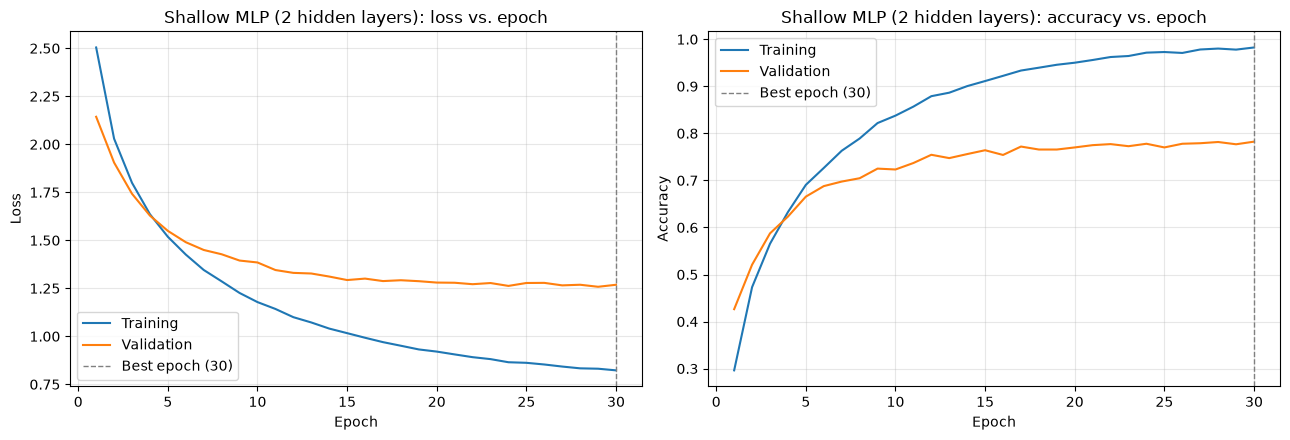

In [17]:
plot_history(shallow_history, shallow_result["best_epoch"], "Shallow MLP (2 hidden layers)")

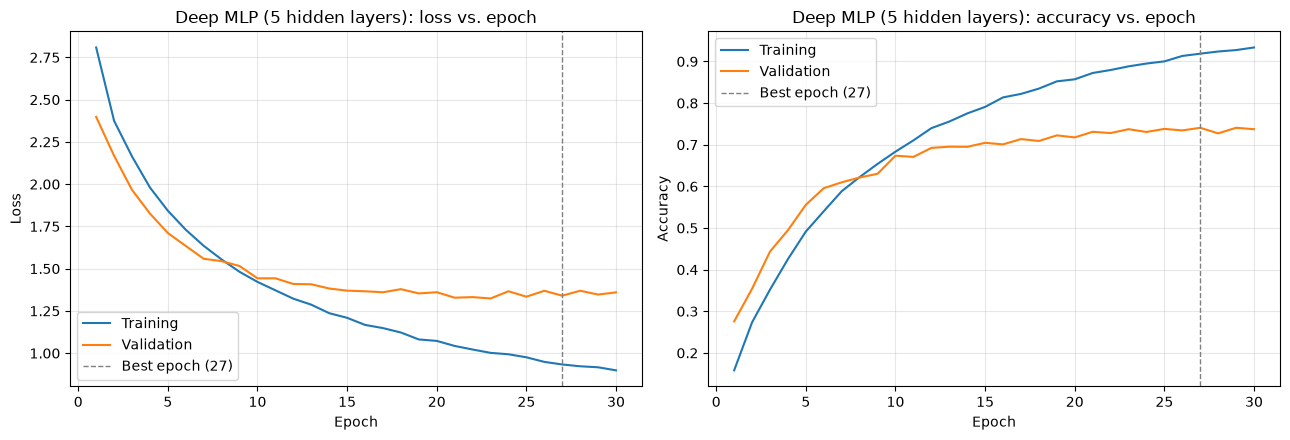

In [18]:
plot_history(deep_history, deep_result["best_epoch"], "Deep MLP (5 hidden layers)")

## 5. Summary of selected settings

In [19]:
summary = pd.DataFrame({
    "setting": ["Loss function", "Optimizer", "Learning rate", "L2 weight decay", "Dropout",
                "Batch size", "Epochs", "Shallow MLP test accuracy", "Deep MLP test accuracy"],
    "value": [BEST_LOSS, BEST_OPT, f"{BEST_LR:g}", f"{BEST_WD:g}", DROPOUT, BATCH_SIZE, EPOCHS,
              f"{comparison_df['test acc'].iloc[0]:.4f}", f"{comparison_df['test acc'].iloc[1]:.4f}"],
})
display(summary)

,setting,value
0,Loss function,CE + Label Smoothing
1,Optimizer,RMSprop
2,Learning rate,0.0003
3,L2 weight decay,1e-05
4,Dropout,0.2
5,Batch size,64
6,Epochs,30
7,Shallow MLP test accuracy,0.7914
8,Deep MLP test accuracy,0.7345
